# ML-Based Phishing Email Detector

## Goal

Train a supervised machine-learning model that predicts whether an email
is phishing/spam or legitimate.

The model will output:

    P(phishing) ∈ [0, 1]

This model will later be loaded by the main LangGraph notebook as one of
the independent signals in the final phishing-risk calculation.

## Initial Model

TF-IDF
   ↓
Logistic Regression
   ↓
Phishing probability

## Dataset

Phishing Email Dataset by Naser Abdullah Alam.

Main file:
    phishing_email.csv

Main fields:
    text_combined
    label

Label convention:
    0 = legitimate
    1 = phishing/spam

## Important

This notebook intentionally starts with a simple, strong baseline.

Later experiments should explore alternatives such as:

- Character + word TF-IDF
- Linear SVM
- Naive Bayes
- XGBoost with engineered email/security features
- Hybrid text + structural models
- Transformer-based classifiers

The deployed model for Notebook 2 will remain behind a common
`predict_proba()` interface regardless of which model eventually wins.

## Environment

Run with the **Python (agentic-phishing)** kernel from the project
root (same venv as `agentic_phishing.ipynb`). Dependencies are installed
from `requirements.txt`:

```powershell
.venv\Scripts\python.exe -m pip install -r requirements.txt
```

The dataset is fetched with `kagglehub`, which caches it under the user
home directory, so reruns do not re-download. This notebook overwrites
`phishing_detector.joblib` and `model_metadata.json` in the project
root, which is where `agentic_phishing.ipynb` loads them from.

In [1]:
import os
import re
import json
import random
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Environment ready.")
print("Random seed:", SEED)

Environment ready.
Random seed: 42


In [2]:
import kagglehub

DATASET_ID = "naserabdullahalam/phishing-email-dataset"

print(f"Downloading: {DATASET_ID}")

dataset_path = kagglehub.dataset_download(
    DATASET_ID
)

print("\nDataset downloaded to:")
print(dataset_path)

C:\Users\91626\OneDrive - Manipal Academy of Higher Education\Desktop\projects\agentic-phishing\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Downloading: naserabdullahalam/phishing-email-dataset



Dataset downloaded to:
C:\Users\91626\.cache\kagglehub\datasets\naserabdullahalam\phishing-email-dataset\versions\1


In [3]:
# Dataset version selector.
#   v1_alam    - normalized phishing_email.csv (lowercased, punctuation stripped)
#   v2_email4s - HF Email4S raw text (mixed case/punctuation, 18.6k emails)
DATASET_VERSION = "v2_email4s"

# v1 runs may replace the deployed artifact directly. Other dataset versions
# must beat the incumbent artifact's test ROC-AUC (see the deploy cell).
DEPLOY_OVERRIDE = DATASET_VERSION == "v1_alam"

print("DATASET_VERSION:", DATASET_VERSION)
print("DEPLOY_OVERRIDE:", DEPLOY_OVERRIDE)

DATASET_VERSION: v2_email4s
DEPLOY_OVERRIDE: False


In [4]:
if DATASET_VERSION == "v2_email4s":
    from huggingface_hub import hf_hub_download

    CSV_PATH = Path(hf_hub_download(
        repo_id="zefang-liu/phishing-email-dataset",
        filename="Phishing_Email.csv",
        repo_type="dataset",
    ))

    raw = pd.read_csv(CSV_PATH)

    raw = raw.rename(
        columns={
            "Email Text": "text_combined",
            "Email Type": "label",
        }
    )

    raw["label"] = raw["label"].map({
        "Safe Email": 0,
        "Phishing Email": 1,
    })

    df = raw[["text_combined", "label"]].copy()

    df["text_combined"] = (
        df["text_combined"]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    df = df[df["text_combined"].str.len() > 0]

    df = df[
        ~df["text_combined"]
        .str.lower()
        .isin(["null", "empty", "nan"])
    ]

    df = (
        df.drop_duplicates(
            subset=["text_combined", "label"]
        )
        .reset_index(drop=True)
    )
else:
    dataset_path = Path(dataset_path)

    csv_candidates = list(
        dataset_path.rglob("phishing_email.csv")
    )

    if not csv_candidates:
        all_csvs = list(dataset_path.rglob("*.csv"))

        print("Could not find phishing_email.csv.")
        print("\nCSV files found:")

        for path in all_csvs:
            print(" -", path)

        raise FileNotFoundError(
            "phishing_email.csv was not found."
        )

    CSV_PATH = csv_candidates[0]

    df = pd.read_csv(
        CSV_PATH,
        low_memory=False
    )

print("Loaded:")
print(CSV_PATH)
print("Shape:", df.shape)

Loaded:
C:\Users\91626\.cache\huggingface\hub\datasets--zefang-liu--phishing-email-dataset\snapshots\34085a032c123ca237f314a01a67909cdea35e34\Phishing_Email.csv
Shape: (17521, 2)


In [5]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Shape: (17521, 2)

Columns:
['text_combined', 'label']


,text_combined,label
0,"re : 6 . 1100 , disc : uniformitarianism , re ...",0
1,the other side of * galicismos * * galicismo *...,0
2,re : equistar deal tickets are you still avail...,0
3,Hello I am your hot lil horny toy.\n I am t...,1
4,software at incredibly low prices ( 86 % lower...,1


In [6]:
print("Shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
display(
    df.isna().sum().sort_values(
        ascending=False
    ).to_frame("missing")
)

print("\nDuplicate rows:", df.duplicated().sum())

Shape: (17521, 2)

Data types:
text_combined      str
label            int64
dtype: object

Missing values:


,missing
text_combined,0
label,0



Duplicate rows: 0


In [7]:
required_columns = {
    "text_combined",
    "label",
}

missing_columns = (
    required_columns
    - set(df.columns)
)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("Required columns found.")

Required columns found.


In [8]:
print("Label distribution:")

label_counts = (
    df["label"]
    .value_counts()
    .sort_index()
)

display(
    label_counts.to_frame("count")
)

print("\nPercentages:")

display(
    (
        df["label"]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
        .to_frame("percentage")
    )
)

Label distribution:


,count
label,
0,10978
1,6543



Percentages:


,percentage
label,
0,62.66
1,37.34


In [9]:
df = df[
    [
        "text_combined",
        "label",
    ]
].copy()

df.rename(
    columns={
        "text_combined": "text",
        "label": "target",
    },
    inplace=True,
)

print(df.shape)
display(df.head())

(17521, 2)


,text,target
0,"re : 6 . 1100 , disc : uniformitarianism , re ...",0
1,the other side of * galicismos * * galicismo *...,0
2,re : equistar deal tickets are you still avail...,0
3,Hello I am your hot lil horny toy.\n I am t...,1
4,software at incredibly low prices ( 86 % lower...,1


In [10]:
# Convert labels to integers.
df["target"] = pd.to_numeric(
    df["target"],
    errors="coerce"
)

# Convert text safely to strings.
df["text"] = df["text"].fillna("").astype(str)

# Remove completely empty emails.
df["text"] = df["text"].str.strip()

before = len(df)

df = df[
    df["text"].str.len() > 0
].copy()

after = len(df)

print(
    f"Removed {before - after:,} empty records."
)

print(
    "\nFinal label values:",
    sorted(df["target"].unique())
)

Removed 0 empty records.



Final label values: [np.int64(0), np.int64(1)]


In [11]:
before = len(df)

df = df.drop_duplicates(
    subset=["text", "target"]
).reset_index(drop=True)

after = len(df)

print(
    f"Removed {before - after:,} exact duplicate emails."
)

print(
    f"Remaining records: {len(df):,}"
)

Removed 0 exact duplicate emails.
Remaining records: 17,521


In [12]:
invalid_labels = ~df["target"].isin([0, 1])

if invalid_labels.any():
    print(
        "Invalid labels found:",
        invalid_labels.sum()
    )

    display(
        df.loc[
            invalid_labels,
            ["target"]
        ].value_counts()
    )

    raise ValueError(
        "Dataset contains labels other than 0 and 1."
    )

print("Binary labels confirmed: 0 / 1")

Binary labels confirmed: 0 / 1


In [13]:
df["text_length"] = df["text"].str.len()
df["word_count"] = (
    df["text"]
    .str.split()
    .str.len()
)

display(
    df.groupby("target")[
        ["text_length", "word_count"]
    ].describe().round(2)
)

text_length                                                   \
             count     mean        std  min    25%     50%      75%   
target                                                                
0          10978.0  3557.17  162652.87  7.0  469.0  1021.0  2054.75   
1           6543.0  1698.83    3471.54  4.0  399.0   763.0  1671.50   

                   word_count                                             \
               max      count    mean       std  min   25%    50%    75%   
target                                                                     
0       17036692.0    10978.0  698.49  33674.78  1.0  83.0  183.5  396.0   
1         129633.0     6543.0  318.69    587.67  1.0  76.0  145.0  310.0   

                   
              max  
target             
0       3527576.0  
1         11625.0

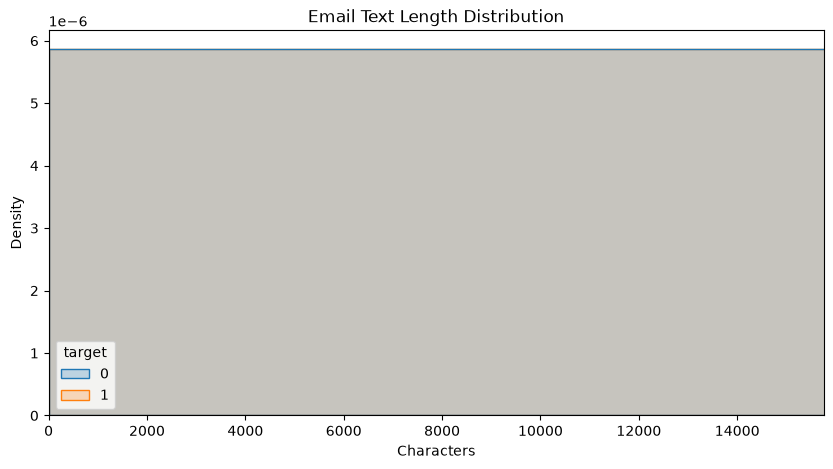

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="text_length",
    hue="target",
    bins=100,
    element="step",
    stat="density",
    common_norm=False,
)

plt.xlim(
    0,
    df["text_length"].quantile(0.99)
)

plt.title("Email Text Length Distribution")
plt.xlabel("Characters")
plt.ylabel("Density")
plt.show()

## EDA: structural feature correlations

Engineered structural features (lengths, ratios, link and punctuation
counts) and their correlation with the phishing label. Correlations here
are computed on the full cleaned dataset and are purely descriptive.

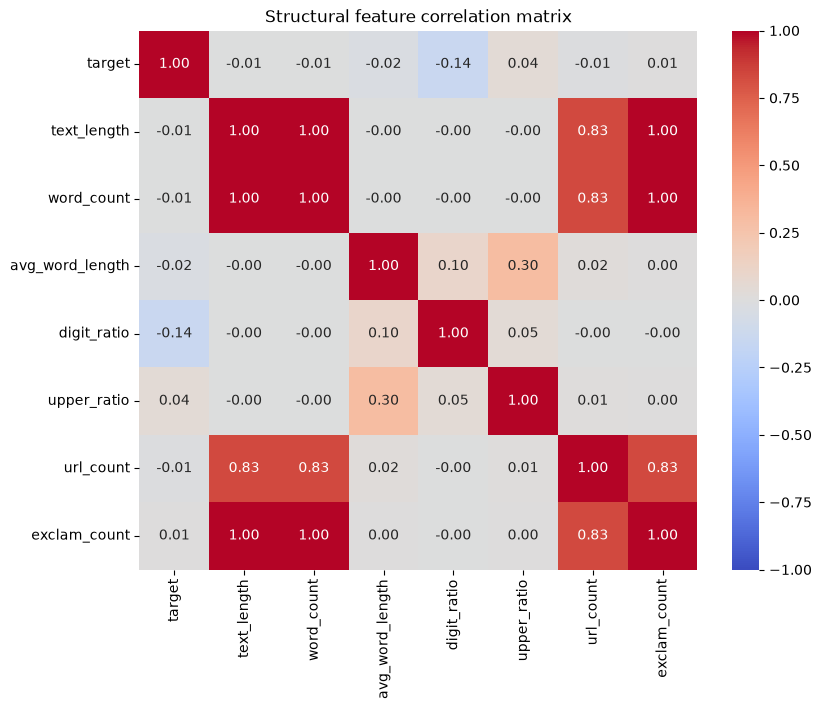

,correlation_with_target
digit_ratio,-0.140700
avg_word_length,-0.024026
url_count,-0.010076
text_length,-0.006981
word_count,-0.006892
exclam_count,0.006603
upper_ratio,0.042788


In [15]:
# EDA: structural features vs target correlation heatmap.
eda_df = df[["target"]].copy()

text = df["text"]

eda_df["text_length"] = text.str.len()
eda_df["word_count"] = text.str.split().str.len()
eda_df["avg_word_length"] = (
    eda_df["text_length"]
    / eda_df["word_count"].clip(lower=1)
)
eda_df["digit_ratio"] = (
    text.str.count(r"\d")
    / eda_df["text_length"]
)
eda_df["upper_ratio"] = (
    text.str.count(r"[A-Z]")
    / eda_df["text_length"]
)
eda_df["url_count"] = text.str.count(r"http|www")
eda_df["exclam_count"] = text.str.count("!")

correlations = eda_df.corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)

plt.title("Structural feature correlation matrix")
plt.show()

display(
    correlations["target"]
    .drop("target")
    .sort_values()
    .to_frame("correlation_with_target")
)

In [16]:
model_df = df[
    ["text", "target"]
].copy()

print("Modeling dataset:")
print(model_df.shape)

print("\nClass counts:")
print(
    model_df["target"]
    .value_counts()
    .sort_index()
)

Modeling dataset:
(17521, 2)

Class counts:
target
0    10978
1     6543
Name: count, dtype: int64


In [17]:
X = model_df["text"]
y = model_df["target"]

# First:
# 70% train
# 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=SEED,
)

# Then divide temporary set equally:
# 15% validation
# 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED,
)

print(
    f"Train:      {len(X_train):,}"
)

print(
    f"Validation: {len(X_val):,}"
)

print(
    f"Test:       {len(X_test):,}"
)

print("\nClass proportions:")

print(
    "\nTrain:\n",
    y_train.value_counts(normalize=True)
)

print(
    "\nValidation:\n",
    y_val.value_counts(normalize=True)
)

print(
    "\nTest:\n",
    y_test.value_counts(normalize=True)
)

Train:      12,264
Validation: 2,628
Test:       2,629

Class proportions:

Train:
 target
0    0.626549
1    0.373451
Name: proportion, dtype: float64

Validation:
 target
0    0.626712
1    0.373288
Name: proportion, dtype: float64

Test:
 target
0    0.626474
1    0.373526
Name: proportion, dtype: float64


In [18]:
# Initial baseline:
#
# TF-IDF → Logistic Regression
#
# This is intentionally simple.
#
# FUTURE EXPERIMENTS:
# - word + character TF-IDF
# - LinearSVC
# - Naive Bayes
# - XGBoost with engineered email/security features
# - hybrid text + structural model
# - transformer-based classifier
#
# We should only replace this baseline after measuring
# whether another architecture materially improves performance.

model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            ngram_range=(1, 2),
            min_df=2,
            max_features=50000,
            sublinear_tf=True,
        )
    ),

    (
        "classifier",
        LogisticRegression(
            C=1.0,
            max_iter=1000,
            solver="liblinear",
            random_state=SEED,
        )
    ),
])

print(model)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=50000, min_df=2,
                                 ngram_range=(1, 2), strip_accents='unicode',
                                 sublinear_tf=True)),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42,
                                    solver='liblinear'))])


In [19]:
print("Training TF-IDF + Logistic Regression...")

model.fit(
    X_train,
    y_train
)

print("Training complete.")

Training TF-IDF + Logistic Regression...


Training complete.


In [20]:
val_pred = model.predict(
    X_val
)

val_prob = model.predict_proba(
    X_val
)[:, 1]

print(
    "Validation predictions generated."
)

Validation predictions generated.


In [21]:
def evaluate_classifier(
    y_true,
    y_pred,
    y_prob,
    split_name="Dataset"
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "f1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "roc_auc": roc_auc_score(
            y_true,
            y_prob
        ),

        "pr_auc": average_precision_score(
            y_true,
            y_prob
        ),
    }

    print(
        f"\n{split_name} Results"
    )
    print("=" * 40)

    for metric, value in metrics.items():
        print(
            f"{metric:12s}: {value:.4f}"
        )

    return metrics

In [22]:
val_metrics = evaluate_classifier(
    y_val,
    val_pred,
    val_prob,
    split_name="Validation"
)


Validation Results
accuracy    : 0.9768
precision   : 0.9802
recall      : 0.9572
f1          : 0.9685
roc_auc     : 0.9981
pr_auc      : 0.9961


In [23]:
print(
    classification_report(
        y_val,
        val_pred,
        target_names=[
            "Legitimate",
            "Phishing"
        ],
        digits=4,
        zero_division=0,
    )
)

              precision    recall  f1-score   support

  Legitimate     0.9749    0.9885    0.9816      1647
    Phishing     0.9802    0.9572    0.9685       981

    accuracy                         0.9768      2628
   macro avg     0.9775    0.9728    0.9751      2628
weighted avg     0.9768    0.9768    0.9767      2628



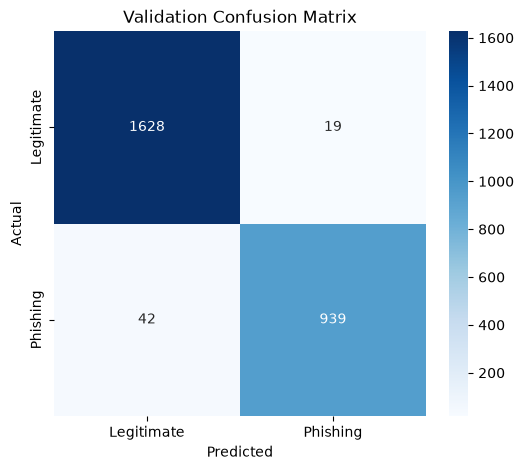

In [24]:
cm = confusion_matrix(
    y_val,
    val_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Legitimate",
        "Phishing"
    ],
    yticklabels=[
        "Legitimate",
        "Phishing"
    ],
)

plt.title("Validation Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [25]:
thresholds = np.arange(
    0.10,
    0.96,
    0.05
)

threshold_results = []

for threshold in thresholds:

    pred = (
        val_prob >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val,
            pred,
            zero_division=0
        ),
        "recall": recall_score(
            y_val,
            pred,
            zero_division=0
        ),
        "f1": f1_score(
            y_val,
            pred,
            zero_division=0
        ),
    })

threshold_df = pd.DataFrame(
    threshold_results
)

display(
    threshold_df.round(4)
)

,threshold,precision,recall,f1
0,0.10,0.6836,1.0000,0.8121
1,0.15,0.7886,1.0000,0.8818
2,0.20,0.8642,0.9990,0.9267
3,0.25,0.9090,0.9980,0.9514
4,0.30,0.9404,0.9969,0.9678
5,0.35,0.9557,0.9898,0.9725
6,0.40,0.9659,0.9827,0.9742
7,0.45,0.9774,0.9704,0.9739
8,0.50,0.9802,0.9572,0.9685
9,0.55,0.9871,0.9378,0.9618


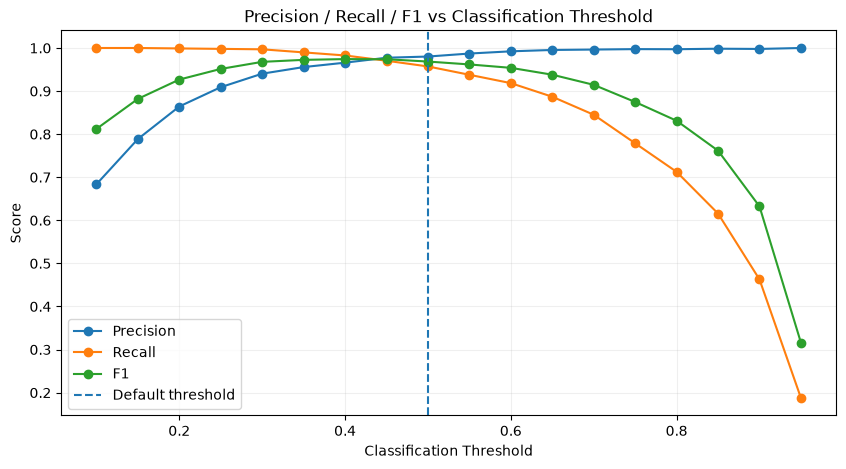

In [26]:
plt.figure(figsize=(10, 5))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    marker="o",
    label="F1"
)

plt.axvline(
    0.5,
    linestyle="--",
    label="Default threshold"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title(
    "Precision / Recall / F1 vs Classification Threshold"
)

plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [27]:
test_pred = model.predict(
    X_test
)

test_prob = model.predict_proba(
    X_test
)[:, 1]

test_metrics = evaluate_classifier(
    y_test,
    test_pred,
    test_prob,
    split_name="Test"
)


Test Results
accuracy    : 0.9798
precision   : 0.9784
recall      : 0.9674
f1          : 0.9729
roc_auc     : 0.9976
pr_auc      : 0.9959


In [28]:
print(
    classification_report(
        y_test,
        test_pred,
        target_names=[
            "Legitimate",
            "Phishing"
        ],
        digits=4,
        zero_division=0,
    )
)

              precision    recall  f1-score   support

  Legitimate     0.9807    0.9872    0.9840      1647
    Phishing     0.9784    0.9674    0.9729       982

    accuracy                         0.9798      2629
   macro avg     0.9795    0.9773    0.9784      2629
weighted avg     0.9798    0.9798    0.9798      2629



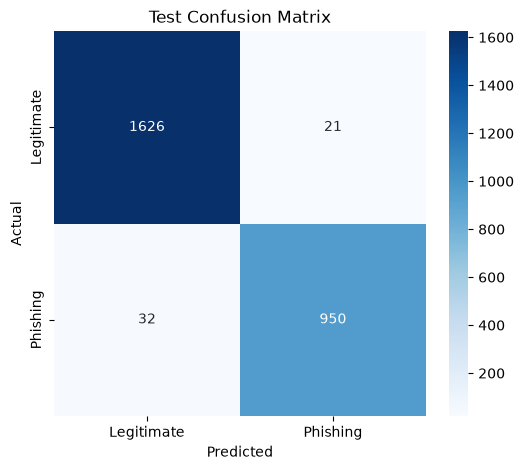

In [29]:
cm_test = confusion_matrix(
    y_test,
    test_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Legitimate",
        "Phishing"
    ],
    yticklabels=[
        "Legitimate",
        "Phishing"
    ],
)

plt.title("Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

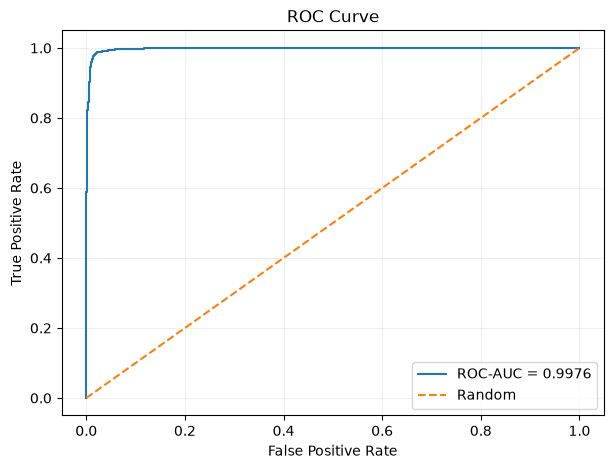

In [30]:
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
)

fpr, tpr, _ = roc_curve(
    y_test,
    test_prob
)

precision_curve, recall_curve, _ = (
    precision_recall_curve(
        y_test,
        test_prob
    )
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {test_metrics['roc_auc']:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

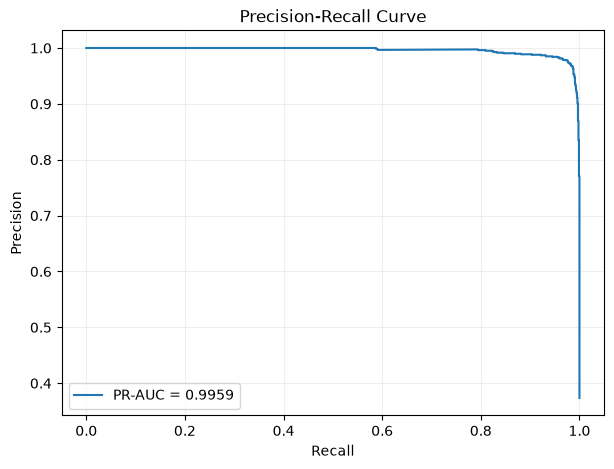

In [31]:
plt.figure(figsize=(7, 5))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"PR-AUC = {test_metrics['pr_auc']:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [32]:
vectorizer = model.named_steps["tfidf"]
classifier = model.named_steps["classifier"]

feature_names = np.array(
    vectorizer.get_feature_names_out()
)

coefficients = classifier.coef_[0]

top_phishing_idx = np.argsort(
    coefficients
)[-30:][::-1]

top_legitimate_idx = np.argsort(
    coefficients
)[:30]

print("Top phishing-associated features:")
print(
    feature_names[
        top_phishing_idx
    ]
)

print("\nTop legitimate-associated features:")
print(
    feature_names[
        top_legitimate_idx
    ]
)

Top phishing-associated features:
['your' 'you' 'our' 'here' 'free' 'click here' 'money' 'no' 'remove'
 '2005' 'click' '2004' 'online' 'site' 'best' 'life' 'save' 'viagra'
 'email' 'now' 'hello' 'for you' 'mobile' 'spamassassin sightings'
 'software' 'quality' 'more' 'sightings' 'low' 'reply']

Top legitimate-associated features:
['enron' 'the' '2002' 'thanks' 'on' 'wrote' 'that' 'language' '2001'
 'attached' 'vince' 'university' '2000' 'url' 'url http' 'date'
 'linguistics' 'edu' 'louise' '713' '01' 'pm' 'enron com' 'of' 'in'
 'listinfo' 'but' 'mailman listinfo' 'mailman' 'gas']


In [33]:
analysis_df = pd.DataFrame({
    "text": X_test.values,
    "actual": y_test.values,
    "predicted": test_pred,
    "probability": test_prob,
})

false_positives = analysis_df[
    (analysis_df["actual"] == 0)
    & (analysis_df["predicted"] == 1)
].sort_values(
    "probability",
    ascending=False
)

false_negatives = analysis_df[
    (analysis_df["actual"] == 1)
    & (analysis_df["predicted"] == 0)
].sort_values(
    "probability",
    ascending=True
)

print(
    "False positives:",
    len(false_positives)
)

print(
    "False negatives:",
    len(false_negatives)
)

False positives: 21
False negatives: 32


In [34]:
print("=" * 80)
print("FALSE POSITIVES")
print("=" * 80)

for i, row in false_positives.head(5).iterrows():

    print(
        f"\nProbability: "
        f"{row['probability']:.4f}"
    )

    print(
        row["text"][:2000]
    )

    print("-" * 80)

FALSE POSITIVES

Probability: 0.8761
You are receiving this email because you signed up to 
receive one of our free reports. If you would prefer 
not to receive messages of this type, please 
unsubscribe by following the instructions at the 
bottom of this message.Dear Fool,Just before Enron plunged......16 of 17 Wall Street analysts were still urging you 
to buy Enron's stock.  While the company piled up debt 
and manufactured imaginary earnings, auditors gave the 
balance sheet a big thumbs-up.  As investors lost 
everything, Enron insiders pocketed millions.AND THAT should make every investor's blood boil!Frankly, the Enrons and Global Crossings of the world 
infuriate me.  All the backroom manipulations dirty 
dealing and cover-ups really make it hard to know who 
you can trust.   And that is why we've created a NEW 
investing service, "David & Tom Gardner's Motley Fool 
Stock Advisor" -- to bring the Motley Fool co-founders' 
extraordinary commitment to honest stock analysis, 
fai

In [35]:
print("=" * 80)
print("FALSE NEGATIVES")
print("=" * 80)

for i, row in false_negatives.head(5).iterrows():

    print(
        f"\nProbability: "
        f"{row['probability']:.4f}"
    )

    print(
        row["text"][:2000]
    )

    print("-" * 80)

FALSE NEGATIVES

Probability: 0.1477
call for papers : the international joint conferences on computer , information and systems sciences and engineering cisse 05 if you received this email in error , please forward it to the appropriate department at your institution please do not reply to this message , your reply will not be received . if you need to contact us , please email us at info @ cisse 2005 . org * international joint conferences on computer , information , * * and systems sciences , and engineering ( cisse 05 ) * * * * * * http : / / www . cisse 2005 . org * * * * * * * december 10 - 20 , 2005 sponsored by : institute of electrical & electronics engineers ( ieee ) university of bridgeport conference overview cisse 05 provides a virtual forum for presentation and discussion of the state - of the - art research on computers , information and systems sciences and engineering . the virtual conference will be conducted through the internet using web - conferencing tools , made 

In [36]:
X_train_final = pd.concat(
    [
        X_train,
        X_val
    ],
    axis=0
)

y_train_final = pd.concat(
    [
        y_train,
        y_val
    ],
    axis=0
)

print(
    "Final training records:",
    len(X_train_final)
)

print(
    "Held-out test records:",
    len(X_test)
)

Final training records: 14892
Held-out test records: 2629


In [37]:
final_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            ngram_range=(1, 2),
            min_df=2,
            max_features=50000,
            sublinear_tf=True,
        )
    ),

    (
        "classifier",
        LogisticRegression(
            C=1.0,
            max_iter=1000,
            solver="liblinear",
            random_state=SEED,
        )
    ),
])

print("Training final deployment model...")

final_model.fit(
    X_train_final,
    y_train_final
)

print("Final model trained.")

Training final deployment model...


Final model trained.


In [38]:
# Artifact paths. The export only happens when this run is allowed to
# replace the deployed artifact (see the ensemble deploy cell below).
ARTIFACT_DIR = Path.cwd()

if not (ARTIFACT_DIR / "README.md").is_file():
    raise RuntimeError(
        "phishing_ml.ipynb must be run from the project root "
        "(README.md not found in the current directory)."
    )

MODEL_ARTIFACT_PATH = (
    ARTIFACT_DIR
    / "phishing_detector.joblib"
)

if DEPLOY_OVERRIDE:
    joblib.dump(
        final_model,
        MODEL_ARTIFACT_PATH
    )

    print("Saved model to:")
    print(MODEL_ARTIFACT_PATH)

    print(
        f"\nSize: "
        f"{MODEL_ARTIFACT_PATH.stat().st_size / 1024**2:.2f} MB"
    )
else:
    print(
        "DEPLOY_OVERRIDE is False; "
        "baseline artifact NOT exported."
    )

DEPLOY_OVERRIDE is False; baseline artifact NOT exported.


In [39]:
metadata = {
    "model_name": "TF-IDF + Logistic Regression",
    "dataset_version": DATASET_VERSION,
    "dataset": {
        "name": "Phishing Email Dataset",
        "source": "Naser Abdullah Alam / Kaggle"
        if DATASET_VERSION == "v1_alam"
        else "Email4S / HF zefang-liu/phishing-email-dataset",
        "text_column": "text_combined",
        "label_column": "label",
        "label_mapping": {
            "0": "legitimate",
            "1": "phishing_spam",
        },
    },
    "preprocessing": {
        "lowercase": True,
        "strip_accents": "unicode",
        "ngram_range": [1, 2],
        "min_df": 2,
        "max_features": 50000,
        "sublinear_tf": True,
    },
    "classifier": {
        "algorithm": "LogisticRegression",
        "C": 1.0,
        "solver": "liblinear",
        "max_iter": 1000,
    },
    "split": {
        "train": 0.70,
        "validation": 0.15,
        "test": 0.15,
        "random_state": SEED,
    },
    "test_metrics": {
        key: float(value)
        for key, value in test_metrics.items()
    },
}

METADATA_PATH = (
    ARTIFACT_DIR
    / "model_metadata.json"
)

if DEPLOY_OVERRIDE:
    with open(
        METADATA_PATH,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(
            metadata,
            f,
            indent=2
        )

    print("Saved metadata to:")
    print(METADATA_PATH)
else:
    print(
        "DEPLOY_OVERRIDE is False; "
        "baseline metadata NOT exported."
    )

DEPLOY_OVERRIDE is False; baseline metadata NOT exported.


## Experiment 1: feature-diverse soft-voting ensemble

Three lightweight, CPU-friendly branches over different views of the text:

1. **word_lr** - word TF-IDF (1-2 grams) + LogisticRegression (the baseline)
2. **char_nb** - hashed char n-grams (3-4) + MultinomialNB
3. **char_svc** - hashed char n-grams (3-4) + calibrated LinearSVC

`HashingVectorizer` bounds memory usage: no vocabulary dictionary is ever
built, and float32 keeps the sparse matrices small. Voting is soft, so the
exported artifact keeps the `predict_proba([text])[0, 1]` contract.

In [40]:
from sklearn.ensemble import VotingClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone
from sklearn.feature_extraction.text import (
    HashingVectorizer,
    TfidfTransformer,
)
from sklearn.pipeline import FeatureUnion
from sklearn.preprocessing import (
    FunctionTransformer,
    MaxAbsScaler,
)
from scipy import sparse

def url_count_feature(raw_documents):
    """Sparse column of per-email URL counts.

    Object dtype avoids Numpy's fixed-width U-dtype, which would
    pad every email to the length of the longest outlier email.
    """
    if hasattr(raw_documents, "to_numpy"):
        docs = raw_documents.to_numpy(dtype=object)
    else:
        docs = np.asarray(raw_documents, dtype=object).ravel()

    counts = np.fromiter(
        (
            len(re.findall(r"https?://|www\.", doc.lower()))
            for doc in docs
        ),
        dtype=np.float32,
        count=len(docs),
    )
    return sparse.csr_matrix(counts.reshape(-1, 1))

def url_count_branch():
    return Pipeline([
        (
            "count",
            FunctionTransformer(url_count_feature),
        ),
        ("scale", MaxAbsScaler()),
    ])

def make_char_pipeline(classifier):
    return Pipeline([
        (
            "features",
            FeatureUnion([
                (
                    "char",
                    Pipeline([
                        (
                            "hash",
                            HashingVectorizer(
                                analyzer="char_wb",
                                ngram_range=(3, 4),
                                n_features=2**18,
                                alternate_sign=False,
                                norm=None,
                                dtype=np.float32,
                            ),
                        ),
                        ("tfidf", TfidfTransformer(sublinear_tf=True)),
                    ]),
                ),
                ("url", url_count_branch()),
            ]),
        ),
        ("classifier", classifier),
    ])

ensemble = VotingClassifier(
    estimators=[
        (
            "word_lr",
            Pipeline([
                (
                    "features",
                    FeatureUnion([
                        (
                            "word_tfidf",
                            TfidfVectorizer(
                                lowercase=True,
                                strip_accents="unicode",
                                ngram_range=(1, 2),
                                min_df=2,
                                max_features=50000,
                                sublinear_tf=True,
                            ),
                        ),
                        ("url", url_count_branch()),
                    ]),
                ),
                (
                    "classifier",
                    LogisticRegression(
                        C=1.0,
                        max_iter=1000,
                        solver="liblinear",
                        random_state=SEED,
                    ),
                ),
            ]),
        ),
        ("char_nb", make_char_pipeline(MultinomialNB())),
        (
            "char_svc",
            make_char_pipeline(
                CalibratedClassifierCV(
                    LinearSVC(C=1.0, dual="auto", random_state=SEED),
                    cv=3,
                    method="sigmoid",
                )
            ),
        ),
    ],
    voting="soft",
    n_jobs=1,
)

print("Training ensemble on the train split...")

ensemble.fit(X_train, y_train)

val_prob_ens = ensemble.predict_proba(X_val)[:, 1]
val_pred_ens = (val_prob_ens >= 0.5).astype(int)

val_metrics_ens = evaluate_classifier(
    y_val,
    val_pred_ens,
    val_prob_ens,
    "Ensemble (validation, equal weights)",
)

Training ensemble on the train split...



Ensemble (validation, equal weights) Results
accuracy    : 0.9772
precision   : 0.9936
recall      : 0.9450
f1          : 0.9687
roc_auc     : 0.9993
pr_auc      : 0.9988


In [41]:
# Voting weights apply at predict time, so one fit covers the whole
# weight search at zero extra training cost.
WEIGHT_PRESETS = [
    (1, 1, 1),
    (2, 1, 1),
    (1, 1, 2),
    (2, 1, 2),
    (3, 1, 2),
    (1, 2, 1),
    (1, 2, 2),
    (2, 2, 1),
]

weight_results = []

for w in WEIGHT_PRESETS:
    ensemble.set_params(weights=w)
    prob = ensemble.predict_proba(X_val)[:, 1]
    weight_results.append({
        "weights": w,
        "roc_auc": roc_auc_score(y_val, prob),
        "pr_auc": average_precision_score(y_val, prob),
    })

weight_df = (
    pd.DataFrame(weight_results)
    .sort_values("roc_auc", ascending=False)
    .reset_index(drop=True)
)

display(weight_df.round(4))

best_weights = tuple(weight_df.iloc[0]["weights"])

ensemble.set_params(weights=best_weights)

test_pred_ens = ensemble.predict(X_test)
test_prob_ens = ensemble.predict_proba(X_test)[:, 1]

test_metrics_ens = evaluate_classifier(
    y_test,
    test_pred_ens,
    test_prob_ens,
    f"Ensemble (test, weights={best_weights})",
)

print("Baseline val ROC-AUC :", round(val_metrics["roc_auc"], 4))
print("Ensemble val ROC-AUC :", round(val_metrics_ens["roc_auc"], 4))
print("Baseline test ROC-AUC:", round(test_metrics["roc_auc"], 4))
print("Ensemble test ROC-AUC:", round(test_metrics_ens["roc_auc"], 4))

,weights,roc_auc,pr_auc
0,"(1, 1, 2)",0.9994,0.9989
1,"(2, 1, 2)",0.9993,0.9988
2,"(1, 1, 1)",0.9993,0.9988
3,"(3, 1, 2)",0.9993,0.9987
4,"(1, 2, 2)",0.9992,0.9986
5,"(2, 1, 1)",0.9992,0.9986
6,"(2, 2, 1)",0.9991,0.9984
7,"(1, 2, 1)",0.9988,0.9976



Ensemble (test, weights=(1, 1, 2)) Results
accuracy    : 0.9844
precision   : 0.9886
recall      : 0.9695
f1          : 0.9789
roc_auc     : 0.9985
pr_auc      : 0.9970
Baseline val ROC-AUC : 0.9981
Ensemble val ROC-AUC : 0.9993
Baseline test ROC-AUC: 0.9976
Ensemble test ROC-AUC: 0.9985


In [42]:
from sklearn.base import clone

# Deployment decision. The artifact is replaced only if:
# 1. the ensemble beats this run's baseline on validation AND test, and
# 2. it meets or beats the incumbent deployed artifact's test ROC-AUC,
#    so a weaker-dataset run cannot degrade the shipped artifact.
INCUMBENT_TEST_ROC_AUC = 0.9993

print("DATASET_VERSION:  ", DATASET_VERSION)
print(
    "Baseline  val/test ROC-AUC:",
    round(val_metrics["roc_auc"], 4),
    "/",
    round(test_metrics["roc_auc"], 4),
)
print(
    "Ensemble  val/test ROC-AUC:",
    round(val_metrics_ens["roc_auc"], 4),
    "/",
    round(test_metrics_ens["roc_auc"], 4),
)
print("Incumbent test ROC-AUC:   ", INCUMBENT_TEST_ROC_AUC)

deploy_ensemble = (
    val_metrics_ens["roc_auc"] > val_metrics["roc_auc"]
    and test_metrics_ens["roc_auc"] > test_metrics["roc_auc"]
    and test_metrics_ens["roc_auc"] >= INCUMBENT_TEST_ROC_AUC
)

print("Deploy ensemble:", deploy_ensemble)

if deploy_ensemble:
    final_ensemble = clone(ensemble)
    final_ensemble.fit(X_train_final, y_train_final)

    joblib.dump(
        final_ensemble,
        MODEL_ARTIFACT_PATH
    )

    ensemble_metadata = {
        "model_name": (
            "Soft-voting ensemble: word TF-IDF LogReg "
            "+ hashed char TF-IDF MultinomialNB "
            "+ hashed char TF-IDF calibrated LinearSVC "
            "+ URL-count feature"
        ),
        "dataset_version": DATASET_VERSION,
        "voting": "soft",
        "weights": list(best_weights),
        "members": [
            "word_tfidf+url+LogisticRegression",
            "hashed_char(3-4)+url+MultinomialNB",
            "hashed_char(3-4)+url+CalibratedLinearSVC",
        ],
        "seed": SEED,
        "test_metrics": {
            key: float(value)
            for key, value in test_metrics_ens.items()
        },
        "baseline_test_metrics": {
            key: float(value)
            for key, value in test_metrics.items()
        },
    }

    with open(
        METADATA_PATH,
        "w",
        encoding="utf-8",
    ) as f:
        json.dump(
            ensemble_metadata,
            f,
            indent=2,
        )

    print("Deployed ensemble to:")
    print(MODEL_ARTIFACT_PATH)

else:
    print(
        "Incumbent artifact retained; "
        "no export this run."
    )

DATASET_VERSION:   v2_email4s
Baseline  val/test ROC-AUC: 0.9981 / 0.9976
Ensemble  val/test ROC-AUC: 0.9993 / 0.9985
Incumbent test ROC-AUC:    0.9993
Deploy ensemble: False
Incumbent artifact retained; no export this run.


## Experiment 2: chi-squared feature selection

Prune the word TF-IDF space from 50,000 to the 30,000 features with the
highest chi-squared scores against the label, then train the same
LogReg. Goal: equal or better metrics at a smaller artifact size.
Analysis-only: does not touch the deployed artifact unless it beats the
ensemble.

In [43]:
from sklearn.feature_selection import (
    SelectKBest,
    chi2,
)

import io

fs_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            ngram_range=(1, 2),
            min_df=2,
            max_features=50000,
            sublinear_tf=True,
        ),
    ),
    ("select", SelectKBest(chi2, k=30000)),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            max_iter=1000,
            solver="liblinear",
            random_state=SEED,
        ),
    ),
])

fs_model.fit(X_train, y_train)

val_prob_fs = fs_model.predict_proba(X_val)[:, 1]
val_pred_fs = (val_prob_fs >= 0.5).astype(int)

val_metrics_fs = evaluate_classifier(
    y_val,
    val_pred_fs,
    val_prob_fs,
    "Feature selection (validation)",
)

test_prob_fs = fs_model.predict_proba(X_test)[:, 1]
test_pred_fs = (test_prob_fs >= 0.5).astype(int)

test_metrics_fs = evaluate_classifier(
    y_test,
    test_pred_fs,
    test_prob_fs,
    "Feature selection (test)",
)

sizes = {}

for name, mdl in [
    ("baseline", model),
    ("ensemble", ensemble),
    ("feature_selection", fs_model),
]:
    buf = io.BytesIO()
    joblib.dump(mdl, buf)
    sizes[name] = buf.getbuffer().nbytes / 1024**2

print("Artifact sizes (MB):")

display(
    pd.Series(sizes, name="size_MB")
    .round(2)
    .to_frame()
)

vectorizer = fs_model.named_steps["tfidf"]
selector = fs_model.named_steps["select"]

feature_names = vectorizer.get_feature_names_out()
selected = selector.get_support()

top_idx = np.argsort(selector.scores_[selected])[-30:][::-1]

print("Top 30 chi2-selected features:")
print(feature_names[selected][top_idx])

print("\nTest ROC-AUC comparison:")
print("baseline:          ", round(test_metrics["roc_auc"], 4))
print("feature selection:", round(test_metrics_fs["roc_auc"], 4))
print("ensemble:         ", round(test_metrics_ens["roc_auc"], 4))


Feature selection (validation) Results
accuracy    : 0.9760
precision   : 0.9791
recall      : 0.9562
f1          : 0.9675
roc_auc     : 0.9978
pr_auc      : 0.9957



Feature selection (test) Results
accuracy    : 0.9783
precision   : 0.9744
recall      : 0.9674
f1          : 0.9709
roc_auc     : 0.9974
pr_auc      : 0.9954


Artifact sizes (MB):


,size_MB
baseline,2.25
ensemble,18.40
feature_selection,2.86


Top 30 chi2-selected features:
['click here' 'your' 'enron' 'here' 'save' 'here to' 'money' 'viagra'
 'be removed' 'our' 'online' 'click' 'remove' 'ect' 'free' 'prescription'
 'removed' '2004' '2005' '2001' 'meds' 'pm' 'hou' 'language' 'hou ect'
 'wrote' '2002' 'vince' 'low' 'university']

Test ROC-AUC comparison:
baseline:           0.9976
feature selection: 0.9974
ensemble:          0.9985


In [44]:
deployment_model = joblib.load(
    MODEL_ARTIFACT_PATH
)

print(
    "Reloaded:",
    type(deployment_model)
)

Reloaded: <class 'sklearn.ensemble._voting.VotingClassifier'>


In [45]:
sample_emails = [

    """
    Subject: Urgent account verification

    Your account has been suspended.
    Verify your identity immediately by clicking
    the following link.
    """,

    """
    Subject: Meeting tomorrow

    Hi everyone,

    Just confirming our meeting tomorrow at 10 AM.

    Thanks.
    """,
]

scores = (
    deployment_model
    .predict_proba(sample_emails)[:, 1]
)

for email, score in zip(
    sample_emails,
    scores
):

    print("=" * 60)
    print(
        f"Phishing score: {score:.4f}"
    )
    print(
        email.strip()[:500]
    )

Phishing score: 0.9654
Subject: Urgent account verification

    Your account has been suspended.
    Verify your identity immediately by clicking
    the following link.
Phishing score: 0.0246
Subject: Meeting tomorrow

    Hi everyone,

    Just confirming our meeting tomorrow at 10 AM.

    Thanks.


In [46]:
def predict_phishing_score(
    email_text: str
) -> float:

    """
    Return the model's phishing probability.

    Output:
        float in [0, 1]

    This is the interface used by the LangGraph notebook.
    """

    if not isinstance(
        email_text,
        str
    ):
        raise TypeError(
            "email_text must be a string."
        )

    if not email_text.strip():
        raise ValueError(
            "email_text cannot be empty."
        )

    score = deployment_model.predict_proba(
        [email_text]
    )[0, 1]

    return float(score)


demo_score = predict_phishing_score(
    sample_emails[0]
)

print(
    f"Demo phishing score: "
    f"{demo_score:.4f}"
)

Demo phishing score: 0.9654


# Final Model Summary

The notebook trained a supervised phishing/spam classifier using:

    TF-IDF
      ↓
    Logistic Regression
      ↓
    P(phishing)

The model was evaluated using:

- Accuracy
- Precision
- Recall
- F1
- ROC-AUC
- PR-AUC
- Confusion matrix
- False-positive / false-negative analysis

The final deployment artifact is:

    phishing_detector.joblib (project root)

Inference contract:

    model.predict_proba([email_text])[0, 1]

Output:

    phishing score ∈ [0, 1]

This score will be passed into the LangGraph phishing-investigation
system as the deterministic ML score.

Future experiments should benchmark stronger or complementary approaches
before replacing the baseline, including character-level TF-IDF, Linear SVM,
Naive Bayes, XGBoost using engineered email/security features, hybrid
text + structural models, and transformer classifiers.